# Glazing performance and thermal mass

Separate solar transmission, heat loss and stored heat rather than reducing every envelope choice to a single U-value.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`GlazingSpec` separates U-value, solar heat gain coefficient and visible transmittance. The first describes thermal transmission, the second solar heat gain and the third optical transmission. Changing all of them is a glazing package, not a pure U-value sensitivity.

A construction's nominal areal heat capacity is `Σ density × specific_heat × thickness`, in J/(m²·K). It describes stored heat per degree per square metre, unlike U-value, which describes a transfer rate. The geometry-pipeline figure shows where physical slabs and constructions remain present even when thermal zone boundaries change.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Compare glazing specifications

U-value and solar heat gain coefficient can affect heating and cooling differently. Visible transmittance is retained independently.

### Read the code and output

Compare both U-value and solar heat gain coefficient in the table. Lower solar gain can reduce cooling but also reduce useful winter gains. The geometry of the opening is unchanged by these properties; opening size and WWR belong to `FacadeSpec` and its layout controls.

Reference: [Resolved roof shells, openings and attached shading](../../docs/figures/roof-and-facade.svg). This linked documentation illustration is separate from the outputs computed below.

,name,u_value_w_m2k,solar_heat_gain_coefficient,visible_transmittance
0,baseline,2.5,0.7,0.65
1,improved,1.1,0.5,0.65


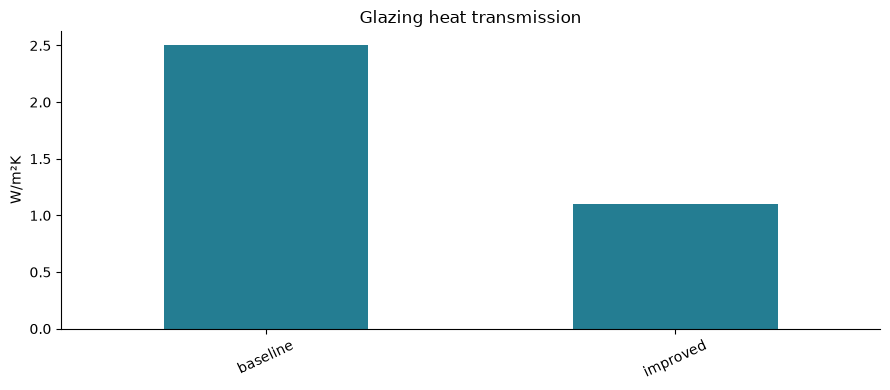

In [2]:
glazing = {"baseline":GlazingSpec(u_value_w_m2k=2.5,solar_heat_gain_coefficient=.7),"improved":GlazingSpec(u_value_w_m2k=1.1,solar_heat_gain_coefficient=.5)}
table([{ "name":name,**g.model_dump()} for name,g in glazing.items()])
bars({name:g.u_value_w_m2k for name,g in glazing.items()},"W/m²K","Glazing heat transmission")

## Quantify nominal areal heat capacity

Areal heat capacity is density × specific heat × thickness summed over layers. It is a useful physical quantity, not a substitute for dynamic simulation.

### Read the code and output

The heavy/light calculation compares nominal material capacity only. This notebook does not run a dynamic heavy-versus-light building experiment, so the bar chart should not be interpreted as measured time lag or cooling savings. Those effects also depend on exposure, controls and the rest of the building.

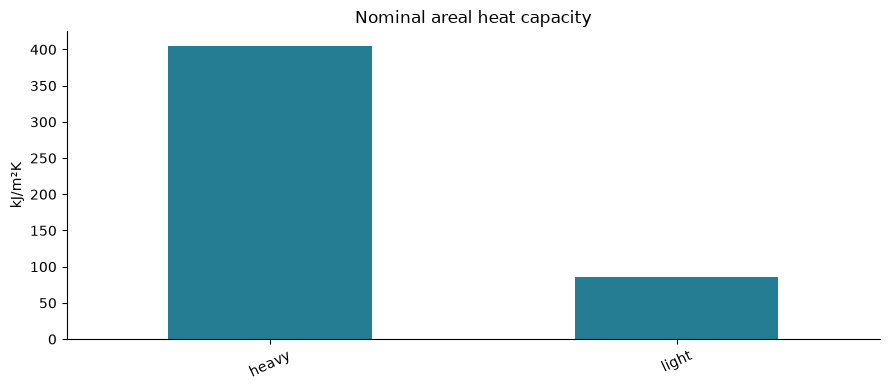

In [3]:
b = building()
heavy = b.envelope.intermediate_floor
light_material = MaterialSpec(name="illustrative timber",conductivity_w_mk=.13,density_kg_m3=450,specific_heat_j_kgk=1600)
light = ConstructionSpec(layers=(LayerSpec(material=light_material,thickness_m=.12),))
assemblies = {"heavy":heavy,"light":light}
bars({name:sum(l.material.density_kg_m3*l.material.specific_heat_j_kgk*l.thickness_m for l in a.layers)/1000 for name,a in assemblies.items()},"kJ/m²K","Nominal areal heat capacity")

## Run a matched glazing comparison

Keep window area and use unchanged. Annual differences reflect both transmission and solar gains, so do not attribute the result to U-value alone.

### Read the code and output

The real simulation compares the two glazing specifications with the same weather and area. Because both U-value and solar gain change, explain any heating difference as the combined glazing response. Do not infer a universal ranking for cooling-disabled or differently shaded buildings from this pair.

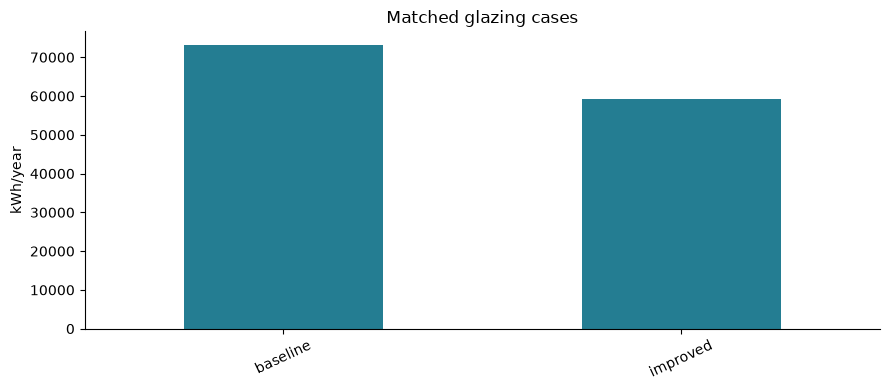

In [4]:
results = {name:EnergyPlusRunner(engine()).run(b.updated(facade=b.facade.updated(glazing=g)),OUT/name) for name,g in glazing.items()}
bars({name:r.scalars["space_heating_demand_kwh"] for name,r in results.items()},"kWh/year","Matched glazing cases")
assert b.facade.default_wwr == .2

## Interpretation and next experiment

Use independently sourced glazing and mass assumptions. Equal U-values do not imply equal dynamic response.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.